# État des datasets avant nettoyage

Ce notebook explore les CSV de `data/raw/delivery` et `data/raw/pickup` avant toute transformation. Il calcule les volumes et valeurs manquantes sur l'ensemble des lignes en lisant les fichiers par blocs. Les graphiques de répartition et de coordonnées utilisent des échantillons pour limiter la mémoire utilisée.

Les tableaux restent affichés dans le notebook. Les tableaux récapitulatifs et graphiques sont aussi enregistrés dans `reports/etat_datasets/`. Aucune donnée brute n'est modifiée.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Fonctionne si le notebook est lancé depuis la racine du dépôt ou depuis data/raw.
cwd = Path.cwd().resolve()
if (cwd / "data" / "raw").is_dir():
    project_root = cwd
elif cwd.name == "raw" and cwd.parent.name == "data":
    project_root = cwd.parent.parent
else:
    raise RuntimeError("Lancez ce notebook depuis la racine du dépôt ou depuis data/raw.")

raw_dir = project_root / "data" / "raw"
report_dir = project_root / "reports" / "etat_datasets"
report_dir.mkdir(parents=True, exist_ok=True)

city_names = {"cq": "Chongqing", "hz": "Hangzhou", "jl": "Jilin", "sh": "Shanghai", "yt": "Yantai"}
gps_columns = {
    "delivery": ["accept_gps_lng", "accept_gps_lat", "delivery_gps_lng", "delivery_gps_lat"],
    "pickup": ["accept_gps_lng", "accept_gps_lat", "pickup_gps_lng", "pickup_gps_lat"],
}
event_columns = {"delivery": "delivery_time", "pickup": "pickup_time"}
CHUNK_SIZE = 100_000
SAMPLE_PER_CHUNK = 1_000
MAX_SAMPLE_PER_FILE = 8_000

print(f"Source : {raw_dir}")
print(f"Rapports : {report_dir}")


Source : /home/yourix/Documents/PROJECTS/IOT/delivery-car/data/raw
Rapports : /home/yourix/Documents/PROJECTS/IOT/delivery-car/reports/etat_datasets


In [2]:
# Parcours complet par blocs pour les compteurs; échantillonnage séparé pour les graphiques.
files = []
for dataset in ("delivery", "pickup"):
    source_dir = raw_dir / dataset
    if not source_dir.is_dir():
        raise FileNotFoundError(f"Dossier absent : {source_dir}")
    files.extend((dataset, path) for path in sorted(source_dir.rglob("*.csv")))
if not files:
    raise FileNotFoundError(f"Aucun CSV trouvé dans {raw_dir}")

file_stats = []
missing_stats = []
daily_counts = {"delivery": {}, "pickup": {}}
samples = []

for file_number, (dataset, path) in enumerate(files):
    city_code = path.stem.rsplit("_", 1)[-1]
    city = city_names.get(city_code, city_code)
    row_count = 0
    empty_row_count = 0
    no_gps_count = 0
    missing_counts = None
    courier_ids = set()
    sample_columns = [
        "lng", "lat", "accept_time", "pickup_time", "delivery_time",
        "time_window_start", "time_window_end", "ds", "aoi_type", "courier_id",
    ]
    file_sample = pd.DataFrame()

    for chunk_number, chunk in enumerate(pd.read_csv(path, chunksize=CHUNK_SIZE)):
        chunk = chunk.replace(r"^\s*$", pd.NA, regex=True)
        row_count += len(chunk)
        empty_row_count += int(chunk.isna().all(axis=1).sum())
        if missing_counts is None:
            missing_counts = chunk.isna().sum().astype("int64")
        else:
            missing_counts = missing_counts.add(chunk.isna().sum(), fill_value=0).astype("int64")

        present_gps = [column for column in gps_columns[dataset] if column in chunk.columns]
        if present_gps:
            no_gps_count += int(chunk[present_gps].isna().all(axis=1).sum())
        if "courier_id" in chunk.columns:
            courier_ids.update(chunk["courier_id"].dropna().astype(str).unique())
        if "ds" in chunk.columns:
            day_counts = chunk["ds"].dropna().astype(str).value_counts()
            for day, count in day_counts.items():
                day = str(day).zfill(4)  # préserve le zéro initial du format MMDD
                daily_counts[dataset][day] = daily_counts[dataset].get(day, 0) + int(count)

        columns_for_sample = [column for column in sample_columns if column in chunk.columns]
        if columns_for_sample and len(chunk):
            candidate = chunk[columns_for_sample].sample(
                n=min(SAMPLE_PER_CHUNK, len(chunk)),
                random_state=42 + file_number + chunk_number,
            )
            file_sample = pd.concat([file_sample, candidate], ignore_index=True)
            if len(file_sample) > MAX_SAMPLE_PER_FILE:
                file_sample = file_sample.sample(MAX_SAMPLE_PER_FILE, random_state=42 + file_number)

    if missing_counts is None:
        missing_counts = pd.Series(dtype="int64")
    gps_present = [column for column in gps_columns[dataset] if column in missing_counts.index]
    file_stats.append({
        "dataset": dataset,
        "ville": city,
        "fichier": str(path.relative_to(raw_dir)),
        "lignes": row_count,
        "colonnes": len(missing_counts),
        "lignes_entierement_vides": empty_row_count,
        "lignes_sans_coordonnees_GPS": no_gps_count,
        "part_sans_GPS_pct": round(100 * no_gps_count / row_count, 2) if row_count else np.nan,
        "coursiers_distincts": len(courier_ids),
    })
    for column, count in missing_counts.items():
        missing_stats.append({
            "fichier": str(path.relative_to(raw_dir)),
            "dataset": dataset,
            "ville": city,
            "colonne": column,
            "valeurs_manquantes": int(count),
            "manquants_pct": 100 * int(count) / row_count if row_count else np.nan,
        })
    if not file_sample.empty:
        file_sample["dataset"] = dataset
        file_sample["ville"] = city
        samples.append(file_sample)

summary = pd.DataFrame(file_stats).sort_values(["dataset", "ville"]).reset_index(drop=True)
missingness = pd.DataFrame(missing_stats)
sample_data = pd.concat(samples, ignore_index=True) if samples else pd.DataFrame()

print(f"Fichiers parcourus : {len(summary)}")
print(f"Lignes brutes comptées : {summary['lignes'].sum():,}")


/tmp/ipykernel_12085/1866496444.py:30: DtypeWarning: Columns (12: pickup_gps_time, 15: accept_gps_time) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk_number, chunk in enumerate(pd.read_csv(path, chunksize=CHUNK_SIZE)):
/tmp/ipykernel_12085/1866496444.py:30: DtypeWarning: Columns (15: accept_gps_time) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk_number, chunk in enumerate(pd.read_csv(path, chunksize=CHUNK_SIZE)):


Fichiers parcourus : 10
Lignes brutes comptées : 10,650,808


In [3]:
# Tables de synthèse avant nettoyage.
summary_view = summary[[
    "dataset", "ville", "lignes", "colonnes", "lignes_entierement_vides",
    "lignes_sans_coordonnees_GPS", "part_sans_GPS_pct", "coursiers_distincts",
]].rename(columns={
    "dataset": "Type", "ville": "Ville", "lignes": "Lignes",
    "colonnes": "Colonnes", "lignes_entierement_vides": "Lignes vides",
    "lignes_sans_coordonnees_GPS": "Lignes sans GPS",
    "part_sans_GPS_pct": "% sans GPS", "coursiers_distincts": "Coursiers distincts",
})
display(summary_view)
summary_view.to_csv(report_dir / "synthese_par_fichier.csv", index=False)

# Taux de valeurs manquantes pour chaque colonne de chaque fichier.
missing_table = missingness.pivot(index="fichier", columns="colonne", values="manquants_pct").fillna(0)
display(missing_table.round(2))
missingness.to_csv(report_dir / "valeurs_manquantes_par_colonne.csv", index=False)


,Type,Ville,Lignes,Colonnes,Lignes vides,Lignes sans GPS,% sans GPS,Coursiers distincts
0,delivery,Chongqing,931351,17,0,0,0.00,1494
1,delivery,Hangzhou,1861600,17,0,0,0.00,1392
2,delivery,Jilin,31415,17,0,0,0.00,57
3,delivery,Shanghai,1483864,17,0,0,0.00,1733
4,delivery,Yantai,206431,17,0,0,0.00,205
5,pickup,Chongqing,1172703,19,0,263196,22.44,2982
6,pickup,Hangzhou,2130456,19,0,647824,30.41,5347
7,pickup,Jilin,261801,19,0,31337,11.97,665
8,pickup,Shanghai,1424406,19,0,382426,26.85,4494
9,pickup,Yantai,1146781,19,0,178735,15.59,2593


colonne,accept_gps_lat,accept_gps_lng,accept_gps_time,accept_time,aoi_id,aoi_type,city,courier_id,delivery_gps_lat,delivery_gps_lng,...,lat,lng,order_id,pickup_gps_lat,pickup_gps_lng,pickup_gps_time,pickup_time,region_id,time_window_end,time_window_start
fichier,,,,,,,,,,,,,,,,,,,,,
delivery/delivery_cq.csv,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0
delivery/delivery_hz.csv,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0
delivery/delivery_jl.csv,3.04,3.04,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0
delivery/delivery_sh.csv,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0
delivery/delivery_yt.csv,1.17,1.17,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0
pickup/pickup_cq.csv,46.67,46.67,46.67,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,27.52,27.52,27.52,0.0,0.0,0.0,0.0
pickup/pickup_hz.csv,51.01,51.01,51.01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,35.06,35.06,35.06,0.0,0.0,0.0,0.0
pickup/pickup_jl.csv,31.26,31.26,31.26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,16.06,16.06,16.06,0.0,0.0,0.0,0.0
pickup/pickup_sh.csv,45.94,45.94,45.94,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,30.98,30.98,30.98,0.0,0.0,0.0,0.0


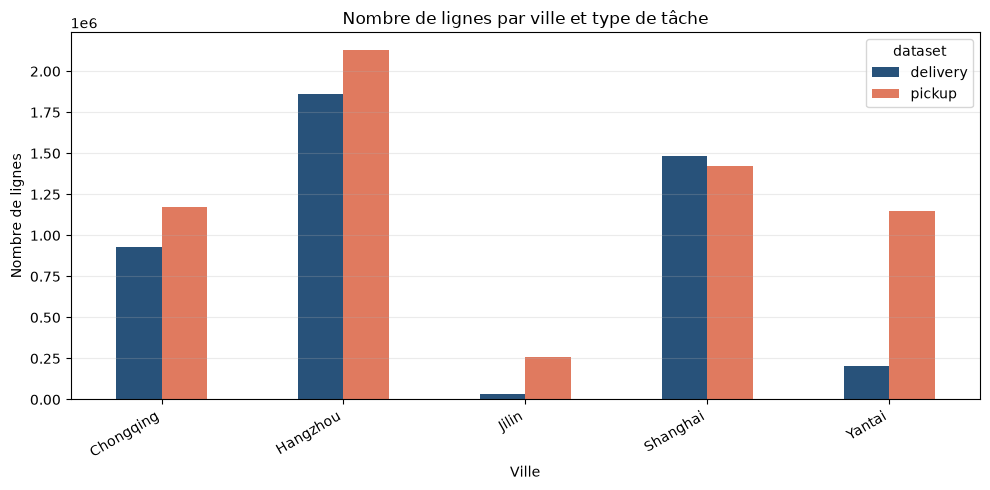

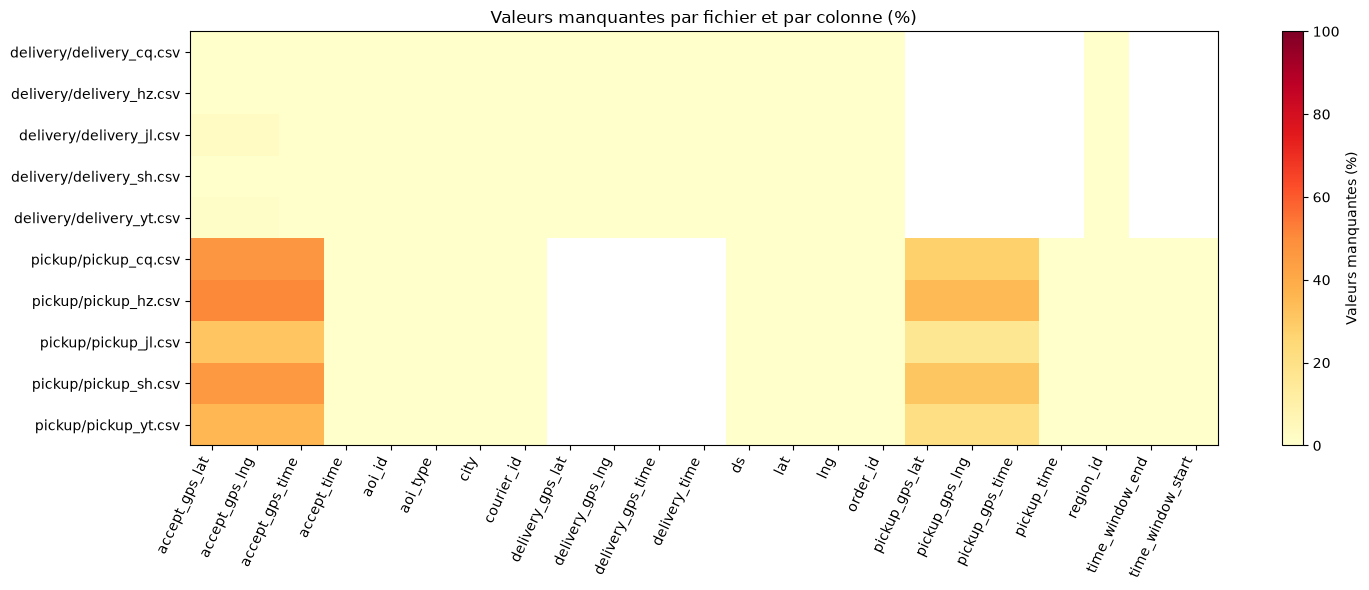

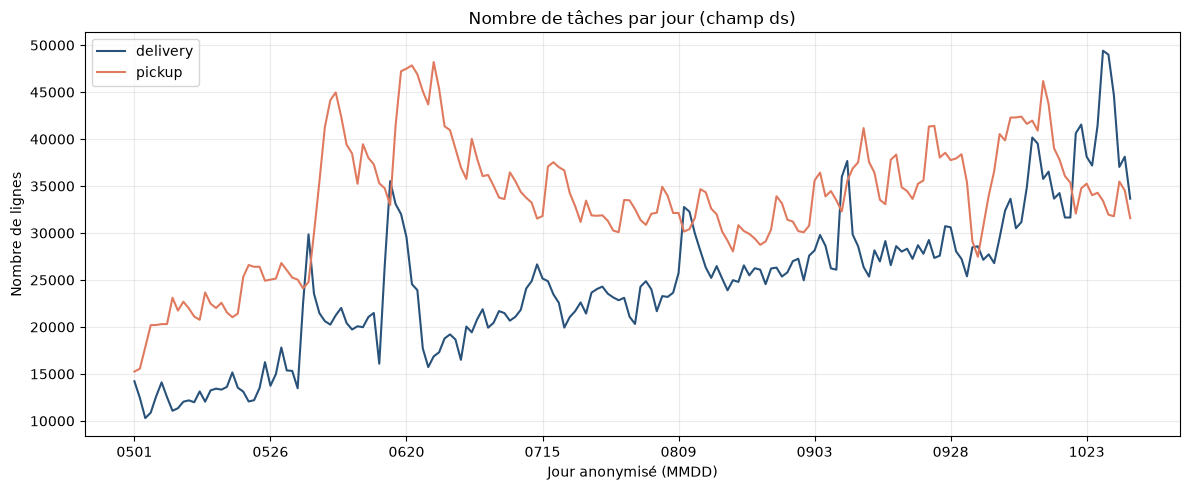

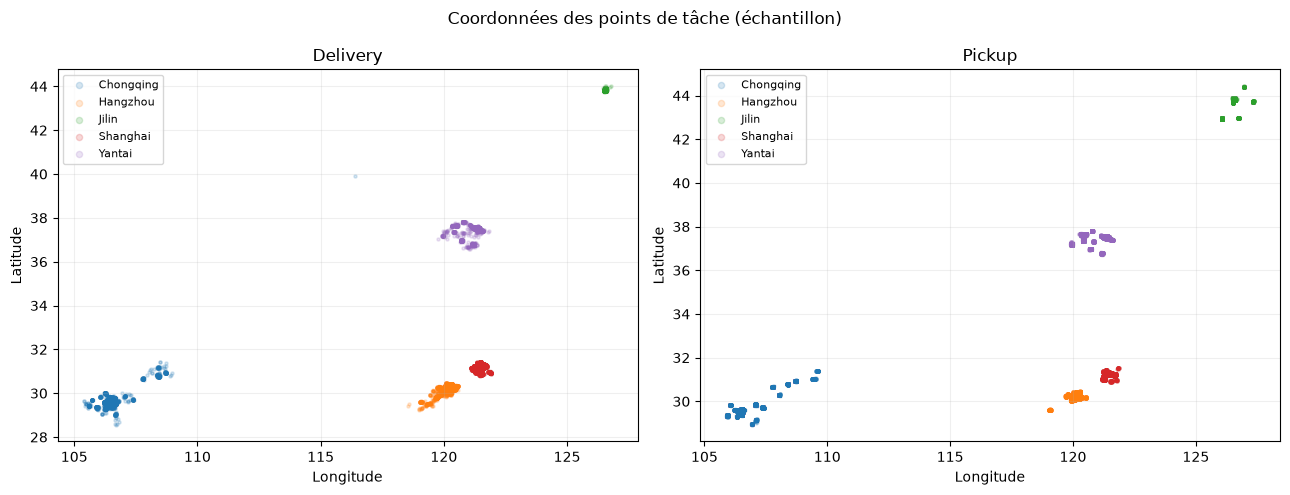

Graphiques et tableaux enregistrés dans : /home/yourix/Documents/PROJECTS/IOT/delivery-car/reports/etat_datasets


In [4]:
# Graphique 1 : volume de lignes par ville et type de tâche.
volume = summary.pivot(index="ville", columns="dataset", values="lignes").fillna(0)
volume = volume.reindex(sorted(volume.index))
ax = volume.plot(kind="bar", figsize=(10, 5), color={"delivery": "#28527a", "pickup": "#e07a5f"})
ax.set_title("Nombre de lignes par ville et type de tâche")
ax.set_xlabel("Ville")
ax.set_ylabel("Nombre de lignes")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.grid(axis="y", alpha=0.25)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(report_dir / "volume_par_ville.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)

# Graphique 2 : carte de chaleur des pourcentages de valeurs manquantes.
missing_matrix = missingness.pivot(index="fichier", columns="colonne", values="manquants_pct")
fig, ax = plt.subplots(figsize=(max(12, 0.65 * len(missing_matrix.columns)), 6))
image = ax.imshow(np.ma.masked_invalid(missing_matrix.to_numpy()), aspect="auto", cmap="YlOrRd", vmin=0, vmax=100)
ax.set_title("Valeurs manquantes par fichier et par colonne (%)")
ax.set_yticks(range(len(missing_matrix.index)), labels=missing_matrix.index)
ax.set_xticks(range(len(missing_matrix.columns)), labels=missing_matrix.columns, rotation=65, ha="right")
fig.colorbar(image, ax=ax, label="Valeurs manquantes (%)")
fig.tight_layout()
fig.savefig(report_dir / "valeurs_manquantes.png", dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)

# Graphique 3 : évolution journalière à partir du champ ds (effectifs exacts).
all_days = sorted({day for counts in daily_counts.values() for day in counts})
if all_days:
    daily_table = pd.DataFrame({
        dataset: [daily_counts[dataset].get(day, 0) for day in all_days]
        for dataset in ("delivery", "pickup")
    }, index=all_days)
    ax = daily_table.plot(figsize=(12, 5), color={"delivery": "#28527a", "pickup": "#e07a5f"})
    ax.set_title("Nombre de tâches par jour (champ ds)")
    ax.set_xlabel("Jour anonymisé (MMDD)")
    ax.set_ylabel("Nombre de lignes")
    ax.grid(alpha=0.25)
    fig = ax.get_figure()
    fig.tight_layout()
    fig.savefig(report_dir / "volume_par_jour.png", dpi=180, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    daily_table.rename_axis("ds").to_csv(report_dir / "volume_par_jour.csv")

# Graphique 4 : dispersion des coordonnées des points de tâche (échantillon par fichier).
if not sample_data.empty and {"lng", "lat"}.issubset(sample_data.columns):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=False, sharey=False)
    for ax, dataset in zip(axes, ("delivery", "pickup")):
        subset = sample_data[sample_data["dataset"] == dataset]
        for city, points in subset.groupby("ville"):
            points = points.dropna(subset=["lng", "lat"])
            ax.scatter(points["lng"], points["lat"], s=5, alpha=0.18, label=city)
        ax.set_title(dataset.capitalize())
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.legend(markerscale=2, fontsize=8)
        ax.grid(alpha=0.2)
    fig.suptitle("Coordonnées des points de tâche (échantillon)")
    fig.tight_layout()
    fig.savefig(report_dir / "dispersion_geographique.png", dpi=180, bbox_inches="tight")
    display(fig)
    plt.close(fig)

print(f"Graphiques et tableaux enregistrés dans : {report_dir}")
